# CodeAlpha Data Visualization Project

## Objective
To visualize chocolate shipment data using Python and Matplotlib, identify patterns in shipment amounts and order statuses, and communicate findings through charts.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sample-chocolate-sales-data-all.xlsx to sample-chocolate-sales-data-all.xlsx


In [ ]:
import pandas as pd

df = pd.read_excel("sample-chocolate-sales-data-all.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7905, 8)


,ShipmentID,SPID,PID,GID,Shipdate,Amount,Boxes,Order_Status
0,S00000012,SP01,P01,G5,2023-12-12,5609.25,374,Delivered
1,S00000042,SP01,P01,G4,2023-10-26,7197.75,450,Delivered
2,S00000058,SP01,P01,G3,2024-06-28,13279.50,1107,Delivered
3,S00000088,SP01,P02,G1,2023-04-03,1919.25,138,Delivered
4,S00000095,SP01,P02,G5,2023-12-25,2324.25,146,Delivered


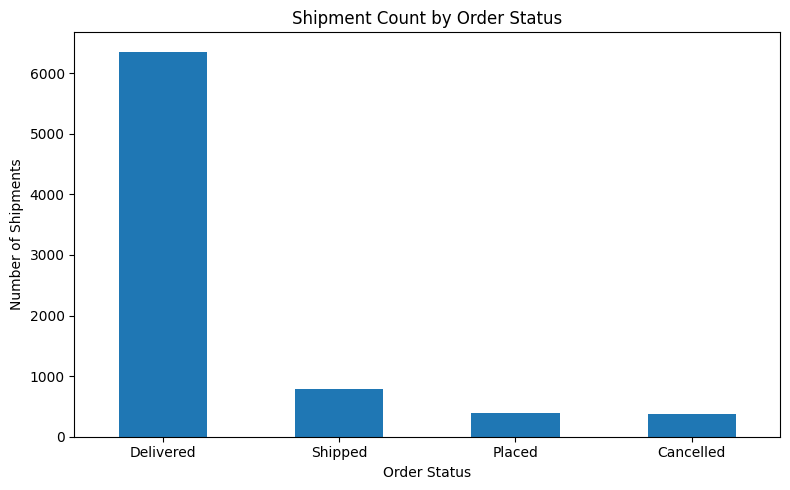

In [ ]:
import matplotlib.pyplot as plt

status_counts = df["Order_Status"].value_counts()

plt.figure(figsize=(8, 5))
status_counts.plot(kind="bar")

plt.title("Shipment Count by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

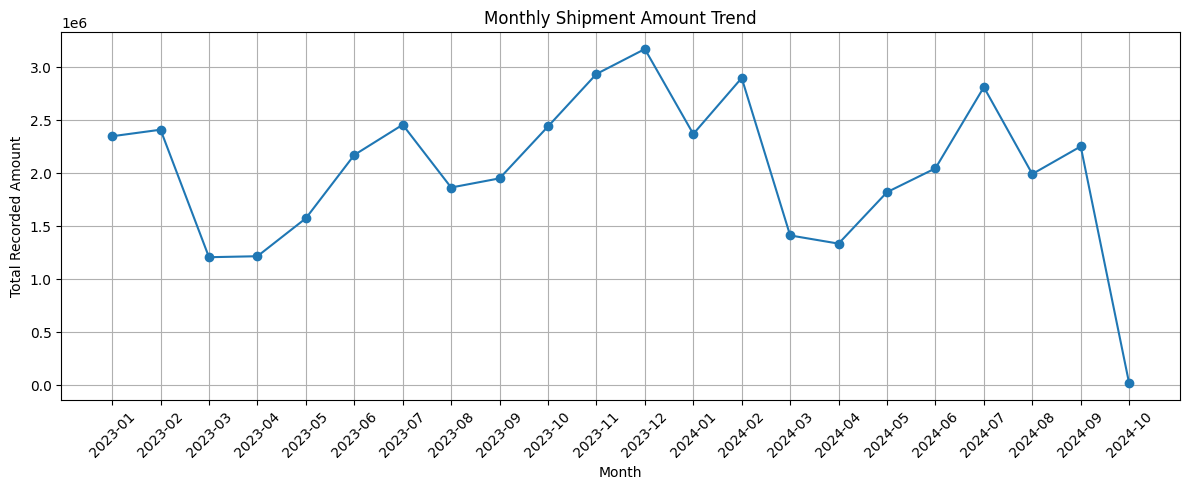

In [ ]:

df["Shipdate"] = pd.to_datetime(df["Shipdate"])
df["Month"] = df["Shipdate"].dt.to_period("M")
monthly_amount = df.groupby("Month")["Amount"].sum()
plt.figure(figsize=(12, 5))
plt.plot(monthly_amount.index.astype(str),
         monthly_amount.values, marker="o")

plt.title("Monthly Shipment Amount Trend")
plt.xlabel("Month")
plt.ylabel("Total Recorded Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

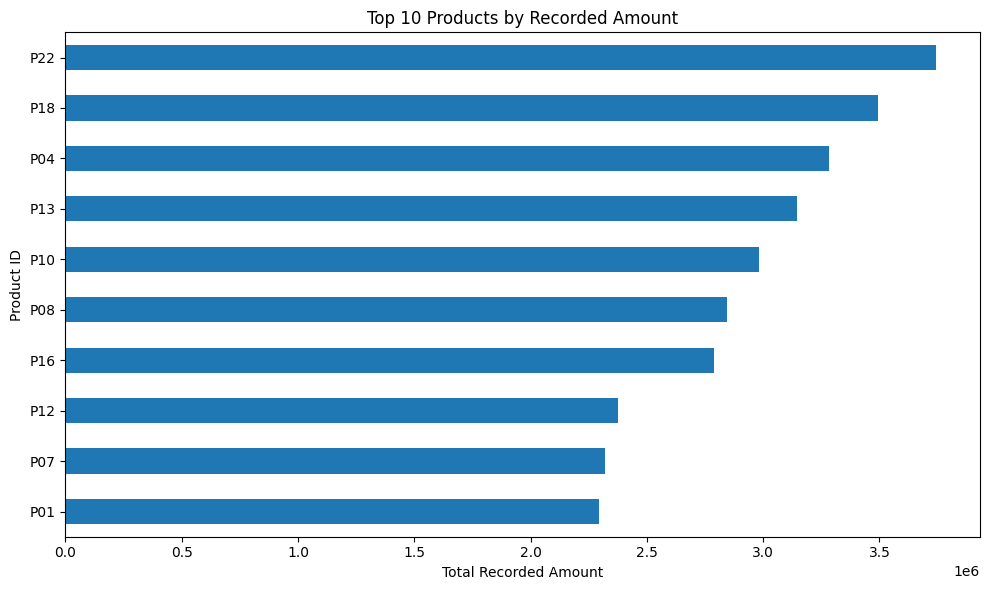

In [ ]:

product_amount = df.groupby("PID")["Amount"].sum()
top_products = product_amount.sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Recorded Amount")
plt.xlabel("Total Recorded Amount")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

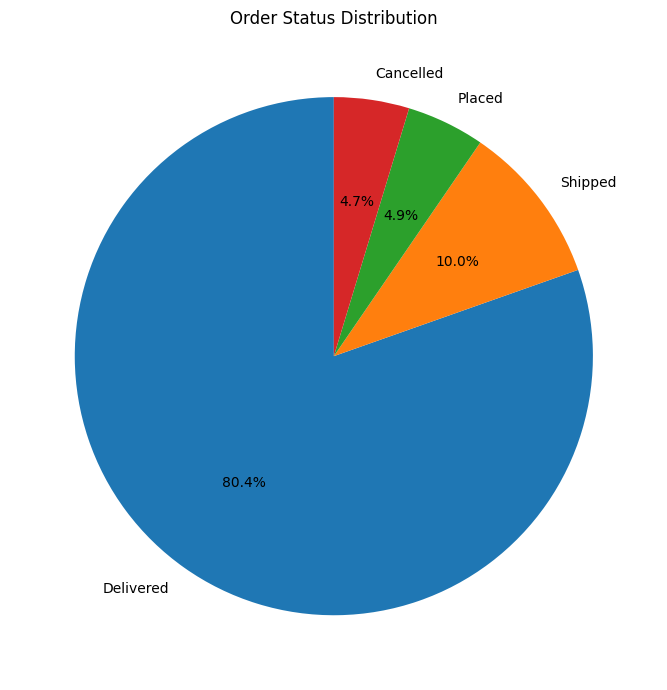

In [ ]:
status_counts = df["Order_Status"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Order Status Distribution")
plt.tight_layout()
plt.show()

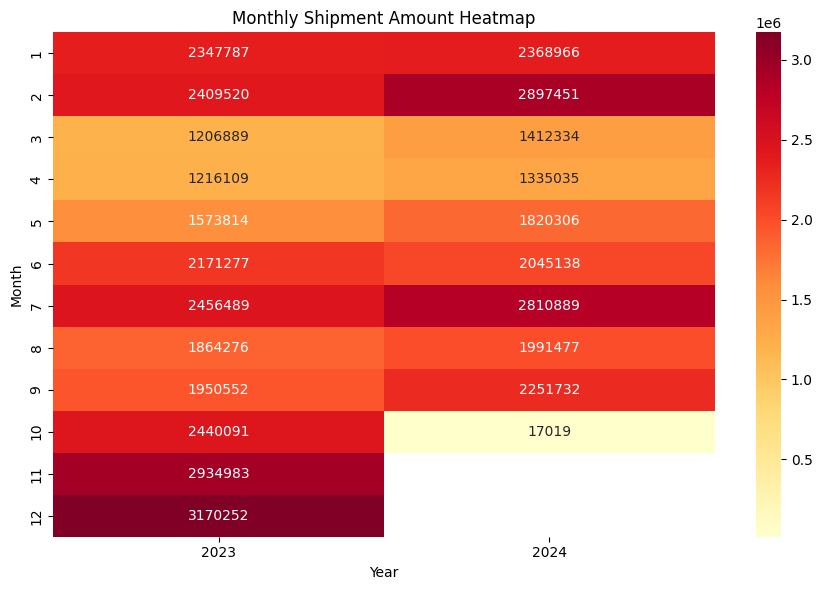

In [ ]:
import seaborn as sns
df["Year"] = df["Shipdate"].dt.year
df["Month_Number"] = df["Shipdate"].dt.month

monthly_pivot = df.pivot_table(
    index="Month_Number",
    columns="Year",
    values="Amount",
    aggfunc="sum"
)
plt.figure(figsize=(9, 6))
sns.heatmap(
    monthly_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Monthly Shipment Amount Heatmap")
plt.xlabel("Year")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import zipfile
import os

os.makedirs("visualization_charts", exist_ok=True)

# Chart 1: Shipment count by order status
plt.figure(figsize=(8, 5))
df["Order_Status"].value_counts().plot(kind="bar")
plt.title("Shipment Count by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualization_charts/01_order_status.png")
plt.close()

# Chart 2: Monthly shipment amount trend
plt.figure(figsize=(12, 5))
monthly_amount = df.groupby(df["Shipdate"].dt.to_period("M"))["Amount"].sum()
plt.plot(monthly_amount.index.astype(str), monthly_amount.values, marker="o")
plt.title("Monthly Shipment Amount Trend")
plt.xlabel("Month")
plt.ylabel("Total Recorded Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("visualization_charts/02_monthly_trend.png")
plt.close()

# Chart 3: Top 10 products
plt.figure(figsize=(10, 6))
df.groupby("PID")["Amount"].sum().nlargest(10).sort_values().plot(kind="barh")
plt.title("Top 10 Products by Recorded Amount")
plt.xlabel("Total Recorded Amount")
plt.ylabel("Product ID")
plt.tight_layout()
plt.savefig("visualization_charts/03_top_products.png")
plt.close()

# Chart 4: Order status distribution
plt.figure(figsize=(7, 7))
df["Order_Status"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", startangle=90
)
plt.title("Order Status Distribution")
plt.ylabel("")
plt.tight_layout()
plt.savefig("visualization_charts/04_status_distribution.png")
plt.close()

# Chart 5: Monthly heatmap
df["Year"] = df["Shipdate"].dt.year
df["Month_Number"] = df["Shipdate"].dt.month
monthly_pivot = df.pivot_table(
    index="Month_Number",
    columns="Year",
    values="Amount",
    aggfunc="sum"
)

plt.figure(figsize=(9, 6))
sns.heatmap(monthly_pivot, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Monthly Shipment Amount Heatmap")
plt.xlabel("Year")
plt.ylabel("Month")
plt.tight_layout()
plt.savefig("visualization_charts/05_monthly_heatmap.png")
plt.close()

# Put all charts into one ZIP file
with zipfile.ZipFile("CodeAlpha_DataVisualization_Charts.zip", "w") as z:
    for file in os.listdir("visualization_charts"):
        z.write(os.path.join("visualization_charts", file), file)

print("All 5 charts saved successfully!")

All 5 charts saved successfully!


In [ ]:
from google.colab import files

files.download("CodeAlpha_DataVisualization_Charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>